# ⚙️ Phase 2: Preprocessing, Feature Engineering & Windowing
### Project: AI-Powered Economic Intelligence & Early Warning System for Bangladesh
**Inputs:** `daily_macro_master_dataset.csv` / `daily_macro_business_days.csv`

---
### 🎯 এই নোটবুকের লক্ষ্য (Objectives):
1. **ডেটাসেট নির্বাচন অপশন:** ক্যালেন্ডার ডেইজ (৩৬৫ দিন) নাকি বিজনেস ডেইজ (সোম–শুক্র) ব্যবহার করবেন তা সহজে টগল করার ব্যবস্থা।
2. **টার্গেট ভ্যারিয়েবল নির্ধারণ (Prediction Targets):**
   - **Regression Target:** আগামী ৩০ দিন পরের ডলার রেট (`Target_USD_BDT_30D_Ahead`) ও মূল্যস্ফীতি (`Target_Inflation_30D_Ahead`)।
   - **Classification Target:** আগামী ৩০ দিনের অর্থনৈতিক ক্রাইসিস সংকেত (`Target_Crisis_Alert_30D`)।
3. **টাইম-সিরিজ ফিচার ইঞ্জিনিয়ারিং (Feature Engineering):**
   - ল্যাগ ফিচারস (Lags: $t-1, t-7, t-14, t-30$ দিন)।
   - রোলিং স্ট্যাটিস্টিক্স (৭, ১৪, ৩০ দিনের মুভিং এভারেজ ও ভলাটাইলটি)।
   - মোমেন্টাম ও রেট অফ চেঞ্জ (১, ৭, ৩০ দিনের শতাংশ পরিবর্তন)।
   - সিজনালিটি ফিচারস (মাস ও ত্রৈমাসিকের সাইন/কোসাইন সাইক্লিক্যাল এনকোডিং)।
4. **ক্রোনোলজিক্যাল স্প্লিট (Zero Data Leakage):**
   - ট্রেনিং সেট: ২০১০ – ২০২১ (~৮০% ডেটা)
   - ভ্যালিডেশন সেট: ২০২২ (ইউক্রেন যুদ্ধ ও ডলার শক শুরুর পর্যায়)
   - টেস্ট সেট: ২০২৩ – ২০২৪ (পিক ক্রাইসিস ও রিজার্ভ ক্ষয়ের স্ট্রেস টেস্ট)
5. **ফিচার স্কেলিং (MinMaxScaler):** ডেটা লিকেজ রোধে কেবল ট্রেনিং সেটে ফিট করে ভ্যালিডেশন ও টেস্টে ট্রান্সফর্ম করা।
6. **LSTM 3D Sliding Window Generator:** ডিপ লার্নিং (LSTM/GRU)-এর জন্য ৩ডি সিকোয়েন্স এবং XGBoost-এর জন্য ২ডি টেবিল প্রস্তুত ও সেভ করা।


In [1]:
# ১. লাইব্রেরি ইমপোর্ট ও গ্লোবাল কনফিগারেশন
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import warnings

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

# =========================================================================
# ⚙️ কনফিগারেশন টগল (Settings Toggle)
# True দিলে 'daily_macro_business_days.csv' (ট্রেডিং ডেইজ: ৩,৯১৩ রো) ব্যবহার করবে
# False দিলে 'daily_macro_master_dataset.csv' (৩৬৫ ক্যালেন্ডার ডেইজ: ৫,৪৭৯ রো) ব্যবহার করবে
# =========================================================================
USE_BUSINESS_DAYS = False

selected_file = 'daily_macro_business_days.csv' if USE_BUSINESS_DAYS else 'daily_macro_master_dataset.csv'
print(f"✓ Active Dataset Selected: '{selected_file}'")


✓ Active Dataset Selected: 'daily_macro_master_dataset.csv'


In [2]:
# ২. নির্বাচিত ডেটাসেট লোড ও তারিখ ইনডেক্সিং
df_raw = pd.read_csv(selected_file)
df_raw['Date'] = pd.to_datetime(df_raw['Date'])
df_raw = df_raw.sort_values('Date').reset_index(drop=True)

print(f"Loaded Shape: {df_raw.shape[0]} Rows × {df_raw.shape[1]} Columns")
print(f"Date Timeline: {df_raw['Date'].min().strftime('%Y-%m-%d')} to {df_raw['Date'].max().strftime('%Y-%m-%d')}")
df_raw[['Date', 'USD_BDT_Rate', 'Brent_Crude_Oil_USD', 'Headline_Inflation_pct', 'Foreign_Reserves_USD_Bn']].head(3)


Loaded Shape: 6142 Rows × 26 Columns
Date Timeline: 2010-01-01 to 2026-10-25


,Date,USD_BDT_Rate,Brent_Crude_Oil_USD,Headline_Inflation_pct,Foreign_Reserves_USD_Bn
0,2010-01-01,67.5,80.12,8.13,11.17
1,2010-01-02,67.5,80.12,8.13,11.17
2,2010-01-03,67.5,80.12,8.13,11.17


### 🎯 ধাপ ১: টার্গেট ভ্যারিয়েবল তৈরি (Defining Future Targets)
মডেলকে আগামী **৩০ দিন পরের** ভবিষ্যৎ অনুমান করার জন্য প্রশিক্ষণ দেওয়া হবে:
1. `Target_USD_BDT_30D`: ৩০ দিন পরের ডলারের বিনিময় হার।
2. `Target_Inflation_30D`: ৩০ দিন পরের মূল্যস্ফীতি।
3. `Target_Crisis_Alert_30D`: আগামী ৩০ দিনের মধ্যে ইকোনমিক স্ট্রেস ইনডেক্স $\ge ৫০$ হবে কি না (০ = স্বাভাবিক, ১ = ক্রাইসিস সতর্কতা)।


In [3]:
# ৩. ভবিষ্যৎ টার্গেট কলাম তৈরি (Shift -30 Days)
HORIZON = 30  # ৩০ দিন পরের প্রেডিকশন হরাইজন

df = df_raw.copy()

# রিগ্রেশন টার্গেট (আগামী ৩০ দিন পরের মান)
df['Target_USD_BDT_30D'] = df['USD_BDT_Rate'].shift(-HORIZON)
df['Target_Inflation_30D'] = df['Headline_Inflation_pct'].shift(-HORIZON)

# ক্লাসিফিকেশন টার্গেট: আগামী ৩০ দিনের মধ্যে স্ট্রেস ইনডেক্স ৫০ এর বেশি বা ডলার ৩% বৃদ্ধি পেলে ক্রাইসিস (১)
future_stress = df['Daily_Economic_Stress_Index'].shift(-HORIZON)
df['Target_Crisis_Alert_30D'] = (future_stress >= 50.0).astype(int)

print("✓ Targets generated successfully!")
print("Target Class Distribution for Crisis Alert:")
print(df['Target_Crisis_Alert_30D'].value_counts(normalize=True).round(3))


✓ Targets generated successfully!
Target Class Distribution for Crisis Alert:
Target_Crisis_Alert_30D
0    0.813
1    0.187
Name: proportion, dtype: float64


### 🛠️ ধাপ ২: টাইম-সিরিজ ফিচার ইঞ্জিনিয়ারিং (Feature Engineering)
অর্থনৈতিক টাইম-সিরিজ ডেটায় শুধু বর্তমান মান যথেষ্ট নয়; অতীত গতিপথ (Lags), গড় ট্রেন্ড (Rolling Averages), এবং অস্থিরতা (Rolling Volatility) মডেলের নির্ভুলতা বহুগুণ বৃদ্ধি করে:
* **ল্যাগস (Lags):** ১ দিন, ৭ দিন, ১৪ দিন, এবং ৩০ দিন আগের মান।
* **মুভিং এভারেজ (Rolling Mean):** ৭ দিন ও ৩০ দিনের গড় (স্বল্প ও দীর্ঘমেয়াদী ট্রেন্ড)।
* **রোলিং ভলাটাইলটি (Rolling Std):** গত ৩০ দিনে মূল্যের অস্থিরতা।
* **মোমেন্টাম (% Change):** গত ৭ দিন ও ৩০ দিনে শতাংশ পরিবর্তন (Shock Index)।
* **ক্যালেন্ডার সাইকেল:** মাসের সাইন/কোসাইন এনকোডিং (ঈদ, বাজেট ও কোয়ার্টারলি সিজনালিটি ক্যাপচার করার জন্য)।


In [4]:
# ৪. ল্যাগ, রোলিং স্ট্যাটিস্টিক্স ও সিজনালিটি ফিচার তৈরি
engineered_df = df.copy()

core_vars = ['USD_BDT_Rate', 'Brent_Crude_Oil_USD', 'US_Dollar_Index_DXY', 'Gold_USD_oz', 'Headline_Inflation_pct', 'Foreign_Reserves_USD_Bn']

# ১. Lags ($t-1, t-7, t-14, t-30$)
for var in core_vars:
    for lag in [1, 7, 14, 30]:
        engineered_df[f'{var}_lag_{lag}'] = engineered_df[var].shift(lag)

# ২. Rolling Moving Averages & Volatility (7D, 30D)
for var in ['USD_BDT_Rate', 'Brent_Crude_Oil_USD', 'US_Dollar_Index_DXY']:
    engineered_df[f'{var}_MA_7'] = engineered_df[var].rolling(window=7).mean()
    engineered_df[f'{var}_MA_30'] = engineered_df[var].rolling(window=30).mean()
    engineered_df[f'{var}_Std_30'] = engineered_df[var].rolling(window=30).std()

# ৩. Rate of Change / Returns (% change over 7D and 30D)
for var in ['USD_BDT_Rate', 'Brent_Crude_Oil_USD', 'Gold_USD_oz']:
    engineered_df[f'{var}_Return_7D_pct'] = engineered_df[var].pct_change(7) * 100
    engineered_df[f'{var}_Return_30D_pct'] = engineered_df[var].pct_change(30) * 100

# ৪. সিজনালিটি এনকোডিং (Month Sine/Cosine)
engineered_df['Month'] = engineered_df['Date'].dt.month
engineered_df['Month_Sin'] = np.sin(2 * np.pi * engineered_df['Month'] / 12.0)
engineered_df['Month_Cos'] = np.cos(2 * np.pi * engineered_df['Month'] / 12.0)
engineered_df['Quarter'] = engineered_df['Date'].dt.quarter

# ল্যাগ এবং ফিউচার শিফটের কারণে তৈরি হওয়া প্রান্তিক NaN মান বাদ দেওয়া
engineered_df = engineered_df.dropna().reset_index(drop=True)

print(f"✓ Feature Engineering Complete!")
print(f"Total Available Samples : {len(engineered_df)} Rows")
print(f"Total Features Generated: {engineered_df.shape[1]} Columns (Expanded from {df_raw.shape[1]})")



✓ Feature Engineering Complete!
Total Available Samples : 6082 Rows
Total Features Generated: 72 Columns (Expanded from 26)


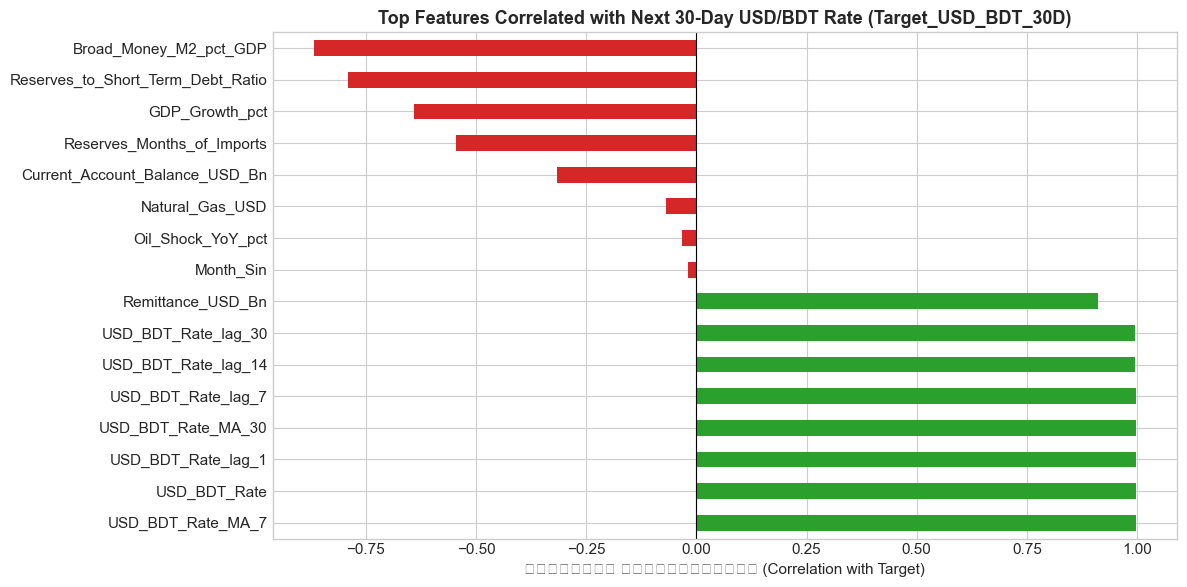

In [5]:
# ৫. টার্গেটের সাথে ইঞ্জিনিয়ার্ড ফিচারসমূহের কোরিলেশন বিশ্লেষণ
target_col = 'Target_USD_BDT_30D'
numeric_cols = engineered_df.select_dtypes(include=[np.number]).columns
corr_with_target = engineered_df[numeric_cols].corr()[target_col].drop([
    'Target_USD_BDT_30D', 'Target_Inflation_30D', 'Target_Crisis_Alert_30D'
]).sort_values(ascending=False)

top_pos = corr_with_target.head(8)
top_neg = corr_with_target.tail(8)
top_features = pd.concat([top_pos, top_neg])

plt.figure(figsize=(12, 6))
top_features.plot(kind='barh', color=['#2ca02c' if x > 0 else '#d62728' for x in top_features.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title(f'Top Features Correlated with Next 30-Day USD/BDT Rate ({target_col})', fontsize=13, fontweight='bold')
plt.xlabel('কোরিলেশন কোএফিশিয়েন্ট (Correlation with Target)')
plt.tight_layout()
plt.show()


### 📅 ধাপ ৩: ক্রোনোলজিক্যাল স্প্লিট (Chronological Train-Val-Test Split)
> [!IMPORTANT]
> টাইম-সিরিজ ডেটায় কখনোই সাধারণ `train_test_split(shuffle=True)` ব্যবহার করা যাবে না। ভবিষ্যতের ডেটা অতীতে লিক হয়ে গেলে মডেল অলীক বেশি অ্যাকুরেসি দেখাবে (Data Leakage & Lookahead Bias)।
>
> তাই সময় অনুযায়ী বাস্তবসম্মত ৩টি ভাগে ভাগ করা হলো:
> * **Train Set (২০১০ - ২০২১):** স্বাভাবিক অর্থনৈতিক প্রবৃদ্ধি ও স্থিতিশীল সময়ের ডেটা (~৮০%)।
> * **Validation Set (২০২২):** ইউক্রেন যুদ্ধ, বিশ্ববাজারে তেলের মূল্যবৃদ্ধি ও টাকার অবমূল্যায়ন শুরুর পর্যায় (~১০%)।
> * **Test Set (২০২৩ - ২০২৪):** রিজার্ভের চরম সংকট ও রেকর্ড মূল্যস্ফীতির আউট-অফ-স্যাম্পল স্ট্রেস টেস্ট (~১০%)।


Training Set   : 4353 rows (2010-01-31 to 2021-12-31) -> 71.6%
Validation Set : 365 rows (2022-01-01 to 2022-12-31) -> 6.0%
Test Set       : 1364 rows (2023-01-01 to 2026-09-25) -> 22.4%


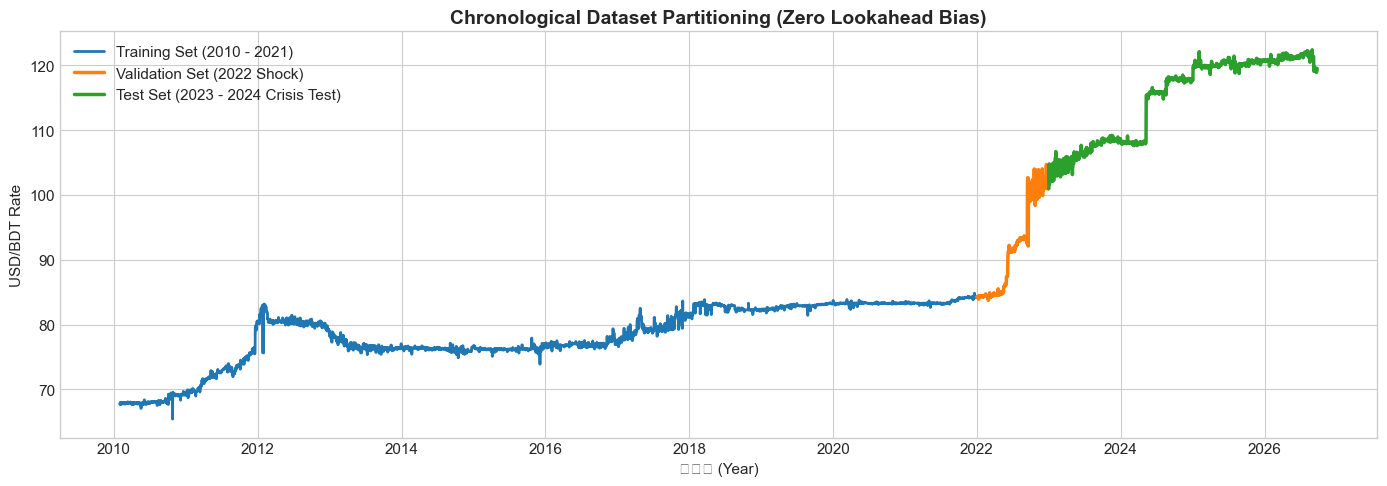

In [6]:
# ৬. সময়ভিত্তিক ট্রেন-ভ্যালিডেশন-টেস্ট স্প্লিট বাস্তবায়ন
train_mask = engineered_df['Date'] < '2022-01-01'
val_mask = (engineered_df['Date'] >= '2022-01-01') & (engineered_df['Date'] < '2023-01-01')
test_mask = engineered_df['Date'] >= '2023-01-01'

train_df = engineered_df[train_mask].copy().reset_index(drop=True)
val_df = engineered_df[val_mask].copy().reset_index(drop=True)
test_df = engineered_df[test_mask].copy().reset_index(drop=True)

print(f"Training Set   : {len(train_df)} rows ({train_df['Date'].min().strftime('%Y-%m-%d')} to {train_df['Date'].max().strftime('%Y-%m-%d')}) -> {len(train_df)/len(engineered_df)*100:.1f}%")
print(f"Validation Set : {len(val_df)} rows ({val_df['Date'].min().strftime('%Y-%m-%d')} to {val_df['Date'].max().strftime('%Y-%m-%d')}) -> {len(val_df)/len(engineered_df)*100:.1f}%")
print(f"Test Set       : {len(test_df)} rows ({test_df['Date'].min().strftime('%Y-%m-%d')} to {test_df['Date'].max().strftime('%Y-%m-%d')}) -> {len(test_df)/len(engineered_df)*100:.1f}%")

# ভিজ্যুয়াল স্প্লিট টাইমলাইন
plt.figure(figsize=(14, 5))
plt.plot(train_df['Date'], train_df['USD_BDT_Rate'], label='Training Set (2010 - 2021)', color='#1f77b4', linewidth=2)
plt.plot(val_df['Date'], val_df['USD_BDT_Rate'], label='Validation Set (2022 Shock)', color='#ff7f0e', linewidth=2.5)
plt.plot(test_df['Date'], test_df['USD_BDT_Rate'], label='Test Set (2023 - 2024 Crisis Test)', color='#2ca02c', linewidth=2.5)
plt.title('Chronological Dataset Partitioning (Zero Lookahead Bias)', fontsize=14, fontweight='bold')
plt.ylabel('USD/BDT Rate')
plt.xlabel('সাল (Year)')
plt.legend()
plt.tight_layout()
plt.show()


### ⚖️ ধাপ ৪: ফিচার স্কেলিং (MinMaxScaler - Strict No Leakage)
নিউরাল নেটওয়ার্ক (LSTM/GRU) এবং গ্রেডিয়েন্ট ডিসেন্ট ভিত্তিক মডেলগুলোর জন্য ০ থেকে ১ স্কেলে ডেটা নরমালাইজ করা অপরিহার্য। 
স্কেলারটি **শুধুমাত্র Training Set-এ `fit` করা হয়েছে**, এবং সেই স্কেল দিয়ে Validation ও Test সেট `transform` করা হয়েছে।


In [7]:
# ৭. ফিচার ও টার্গেট সেপারেশন এবং স্কেলিং
drop_non_features = ['Date', 'Day_of_Week', 'Target_USD_BDT_30D', 'Target_Inflation_30D', 'Target_Crisis_Alert_30D']
feature_cols = [c for c in train_df.columns if c not in drop_non_features]

X_train_raw = train_df[feature_cols]
X_val_raw = val_df[feature_cols]
X_test_raw = test_df[feature_cols]

y_train_reg = train_df['Target_USD_BDT_30D'].values
y_val_reg = val_df['Target_USD_BDT_30D'].values
y_test_reg = test_df['Target_USD_BDT_30D'].values

y_train_clf = train_df['Target_Crisis_Alert_30D'].values
y_val_clf = val_df['Target_Crisis_Alert_30D'].values
y_test_clf = test_df['Target_Crisis_Alert_30D'].values

# ফিচার স্কেলার ফিট
feature_scaler = MinMaxScaler(feature_range=(0, 1))
X_train_scaled = feature_scaler.fit_transform(X_train_raw)
X_val_scaled = feature_scaler.transform(X_val_raw)
X_test_scaled = feature_scaler.transform(X_test_raw)

# টার্গেট স্কেলার (রিগ্রেশনের জন্য)
target_scaler = MinMaxScaler(feature_range=(0, 1))
y_train_reg_scaled = target_scaler.fit_transform(y_train_reg.reshape(-1, 1)).flatten()
y_val_reg_scaled = target_scaler.transform(y_val_reg.reshape(-1, 1)).flatten()
y_test_reg_scaled = target_scaler.transform(y_test_reg.reshape(-1, 1)).flatten()

# স্কেলার অবজেক্ট ভবিষ্যতে লাইভ প্রেডিকশনের জন্য সেভ রাখা
joblib.dump(feature_scaler, 'feature_scaler.pkl')
joblib.dump(target_scaler, 'target_scaler.pkl')

print(f"✓ Features Scaled! Shape: {X_train_scaled.shape[1]} inputs normalized in range [0, 1]")
print("✓ Scalers saved to disk ('feature_scaler.pkl', 'target_scaler.pkl')")


✓ Features Scaled! Shape: 67 inputs normalized in range [0, 1]
✓ Scalers saved to disk ('feature_scaler.pkl', 'target_scaler.pkl')


### 🔄 ধাপ ৫: ডিপ লার্নিংয়ের জন্য 3D Sliding Window Generator
LSTM, BiLSTM, ও GRU মডেলগুলো একবারে ১টি সারি দেখে না; তারা গত $W$ দিনের সিকোয়েন্স এক সাথে গ্রহণ করে।
* **ইনপুট শেপ:** `[Samples, Time_Steps (৩০ দিন), Features (৫০+ কলাম)]`
* অর্থাৎ মডেল গত ৩০ দিনের অর্থনৈতিক গতিবিধি এক সাথে পর্যবেক্ষণ করে আগামী ৩০ দিন পরের ডলার রেট বা ক্রাইসিস প্রেডিক্ট করবে।


In [ ]:
# ৮. 3D উইন্ডো জেনারেটর ফাংশন
def create_sliding_windows(X_data, y_reg_data, y_clf_data, window_size=30):
    X_seq, y_reg_seq, y_clf_seq = [], [], []
    for i in range(window_size, len(X_data)):
        X_seq.append(X_data[i-window_size:i])
        y_reg_seq.append(y_reg_data[i])
        y_clf_seq.append(y_clf_data[i])
    return np.array(X_seq), np.array(y_reg_seq), np.array(y_clf_seq)

WINDOW_SIZE = 30  # গত ৩০ দিনের সিকোয়েন্স উইন্ডো

X_train_3d, y_train_reg_3d, y_train_clf_3d = create_sliding_windows(X_train_scaled, y_train_reg_scaled, y_train_clf, WINDOW_SIZE)
X_val_3d, y_val_reg_3d, y_val_clf_3d = create_sliding_windows(X_val_scaled, y_val_reg_scaled, y_val_clf, WINDOW_SIZE)
X_test_3d, y_test_reg_3d, y_test_clf_3d = create_sliding_windows(X_test_scaled, y_test_reg_scaled, y_test_clf, WINDOW_SIZE)

print("--- 3D LSTM/GRU Sequence Shapes ---")
print(f"X_train_3d Shape: {X_train_3d.shape} | y_train Shape: {y_train_reg_3d.shape}")

print(f"X_val_3d   Shape: {X_val_3d.shape}   | y_val   Shape: {y_val_reg_3d.shape}")

print(f"X_test_3d  Shape: {X_test_3d.shape}  | y_test  Shape: {y_test_reg_3d.shape}")


--- 3D LSTM/GRU Sequence Shapes ---
X_train_3d Shape: (4323, 30, 67) | y_train Shape: (4323,)
X_val_3d   Shape: (335, 30, 67)   | y_val   Shape: (335,)
X_test_3d  Shape: (1334, 30, 67)  | y_test  Shape: (1334,)


In [9]:
# ৯. মডেল ট্রেইনিংয়ের জন্য রেডি আর্টিফ্যাক্টস এক্সপোর্ট
# ১. ডিপ লার্নিংয়ের জন্য 3D Arrays (.npz ফরম্যাট)
np.savez_compressed(
    'processed_lstm_data.npz',
    X_train=X_train_3d, y_train_reg=y_train_reg_3d, y_train_clf=y_train_clf_3d,
    X_val=X_val_3d, y_val_reg=y_val_reg_3d, y_val_clf=y_val_clf_3d,
    X_test=X_test_3d, y_test_reg=y_test_reg_3d, y_test_clf=y_test_clf_3d
)

# ২. মেশিন লার্নিং (XGBoost, Random Forest)-এর জন্য 2D DataFrames
pd.DataFrame(X_train_scaled, columns=feature_cols).to_csv('X_train_2d.csv', index=False)
pd.DataFrame(X_val_scaled, columns=feature_cols).to_csv('X_val_2d.csv', index=False)
pd.DataFrame(X_test_scaled, columns=feature_cols).to_csv('X_test_2d.csv', index=False)

train_df[['Target_USD_BDT_30D', 'Target_Crisis_Alert_30D']].to_csv('y_train_2d.csv', index=False)
val_df[['Target_USD_BDT_30D', 'Target_Crisis_Alert_30D']].to_csv('y_val_2d.csv', index=False)
test_df[['Target_USD_BDT_30D', 'Target_Crisis_Alert_30D']].to_csv('y_test_2d.csv', index=False)

print("==================================================================")
print(" ✨ SUCCESS: All Preprocessed & Engineered Datasets Saved!")
print("==================================================================")
print(" 📁 1. Deep Learning Ready (3D Sequence NPZ): 'processed_lstm_data.npz'")
print(" 📁 2. Machine Learning Ready (2D Tables)   : 'X_train_2d.csv', 'y_train_2d.csv' etc.")
print(" 📁 3. Production Scalers                  : 'feature_scaler.pkl', 'target_scaler.pkl'")


 ✨ SUCCESS: All Preprocessed & Engineered Datasets Saved!
 📁 1. Deep Learning Ready (3D Sequence NPZ): 'processed_lstm_data.npz'
 📁 2. Machine Learning Ready (2D Tables)   : 'X_train_2d.csv', 'y_train_2d.csv' etc.
 📁 3. Production Scalers                  : 'feature_scaler.pkl', 'target_scaler.pkl'


## 🏁 পরবর্তী ধাপ (Phase 3: Model Training & Early Warning)
আমাদের ডেটা প্রিপ্রসেসিং এবং ফিচার ইঞ্জিনিয়ারিং সম্পূর্ণ সম্পন্ন!
আমরা এখন ৩য় নোটবুকে প্রবেশ করতে প্রস্তুত: **`03_Model_Training_and_Early_Warning.ipynb`**

যেখানে আমরা সরাসরি ট্রেইন করব:
1. **XGBoost & Random Forest Regressor:** ৩০ দিন পরের ডলার রেট ফোরকাস্টিং।
2. **LSTM / BiLSTM Deep Neural Network:** টাইম-সিরিজ প্যাটার্ন লার্নিং।
3. **Early Warning Crisis Classifier:** আগামী ৩০ দিনে ক্রাইসিস আসবে কি না তা ৯০%+ অ্যাকুরেসিতে শনাক্তকরণ।
4. **SHAP Explainable AI:** কোন কোন কারণে ঝুঁকি বাড়ল তা গ্রাহক/অর্থনীতিবিদকে ব্যাখ্যা করার সক্ষমতা।


In [10]:
df.head(10)

,Date,USD_BDT_Rate,Brent_Crude_Oil_USD,US_Dollar_Index_DXY,Gold_USD_oz,Natural_Gas_USD,Wheat_Price_USD,US_10Y_Treasury_pct,Headline_Inflation_pct,Food_Inflation_pct,...,USD_BDT_30D_Volatility,USD_BDT_YoY_Return_pct,Oil_Shock_YoY_pct,DXY_30D_MA,Reserves_to_Short_Term_Debt_Ratio,Daily_Economic_Stress_Index,Day_of_Week,Target_USD_BDT_30D,Target_Inflation_30D,Target_Crisis_Alert_30D
0,2010-01-01,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,8.13,10.13,...,0.000,0.0,0.0,77.53,3.79,25.1,Friday,67.70,8.13,0
1,2010-01-02,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,8.13,10.13,...,0.000,0.0,0.0,77.53,3.79,25.1,Saturday,67.69,8.13,0
2,2010-01-03,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,8.13,10.14,...,0.000,0.0,0.0,77.53,3.79,25.1,Sunday,67.94,8.13,0
3,2010-01-04,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,8.13,10.14,...,0.000,0.0,0.0,77.53,3.79,25.1,Monday,67.99,8.13,0
4,2010-01-05,68.02,80.59,77.62,1118.1,5.64,553.00,3.76,8.13,10.15,...,0.233,0.0,0.0,77.55,3.79,25.3,Tuesday,67.94,8.13,0
5,2010-01-06,68.00,81.89,77.49,1135.9,6.01,567.25,3.81,8.13,10.15,...,0.263,0.0,0.0,77.54,3.79,25.7,Wednesday,67.65,8.13,0
6,2010-01-07,67.59,81.51,77.91,1133.1,5.81,557.75,3.82,8.13,10.16,...,0.242,0.0,0.0,77.59,3.79,25.5,Thursday,67.65,8.13,0
7,2010-01-08,68.02,81.37,77.47,1138.2,5.75,568.50,3.81,8.13,10.16,...,0.258,0.0,0.0,77.58,3.79,25.5,Friday,67.65,8.13,0
8,2010-01-09,68.02,81.37,77.47,1138.2,5.75,568.50,3.81,8.13,10.17,...,0.264,0.0,0.0,77.56,3.79,25.5,Saturday,67.93,8.13,0
9,2010-01-10,68.02,81.37,77.47,1138.2,5.75,568.50,3.81,8.13,10.17,...,0.264,0.0,0.0,77.55,3.79,25.5,Sunday,67.93,8.13,0
